# Assignment 3: SLCM Classification Analysis
CS 430 | Student: **[add your name]**


Prediction question: Can household and housing information help identify households with $3,000 or more in past-due rent?

** I used OpenAI Codex to help set up the notebook and Format **

## Part 1 - Understand the Classification Problem
### 1. Explore the dataset (7 points)
- Load the CSV. Display five rows, the data shape, the column names, and missing-value counts.
- Identify one numerical and one categorical feature.
- Answer: Why must past_due_rent be excluded from the input features?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("SLCM_rent_arrears_student_clean.csv")
df.head()

,record_id,adults_in_household,children_in_household,household_has_65plus,monthly_household_income,income_sources,employment_status,has_housing_voucher,eviction_in_progress,behind_on_utilities,main_reason_behind_on_rent,intake_quarter,monthly_rent,past_due_rent
0,SLCM_0001,1,1,No,293.0,"Food benefits - TANF/SNAP, No income, Other",Unemployed but want to find work,No,I don't know,Yes,Other,2026-Q1,1560.0,3100.0
1,SLCM_0002,0,3,No,2000.0,Child support,Employed,No,I don't know,Yes,Unexpected expense,2026-Q3,1550.0,7300.0
2,SLCM_0003,1,0,No,400.0,Food benefits - TANF/SNAP,Unemployed but want to find work,I don't know,Yes,Yes,Lost a job/had hours cut,2025-Q4,0.0,6000.0
3,SLCM_0004,2,0,No,2500.0,Full-time employment,Unemployed and not looking for work,No,Yes,Yes,Lost a job/had hours cut,2026-Q2,1299.0,2500.0
4,SLCM_0005,1,2,No,14.0,Part-time employment,Employed,No,Yes,No,Unexpected expense,2025-Q4,1105.5,1205.5


In [3]:
print("Shape of Data:", df.shape)
df.info()

Shape of Data: (1754, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1754 entries, 0 to 1753
Data columns (total 14 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   record_id                   1754 non-null   object 
 1   adults_in_household         1754 non-null   int64  
 2   children_in_household       1754 non-null   int64  
 3   household_has_65plus        1754 non-null   object 
 4   monthly_household_income    1646 non-null   float64
 5   income_sources              1754 non-null   object 
 6   employment_status           1754 non-null   object 
 7   has_housing_voucher         1754 non-null   object 
 8   eviction_in_progress        1753 non-null   object 
 9   behind_on_utilities         1747 non-null   object 
 10  main_reason_behind_on_rent  1738 non-null   object 
 11  intake_quarter              1754 non-null   object 
 12  monthly_rent                1746 non-null   float64
 13  past_du

In [4]:
df.columns

Index(['record_id', 'adults_in_household', 'children_in_household',
       'household_has_65plus', 'monthly_household_income', 'income_sources',
       'employment_status', 'has_housing_voucher', 'eviction_in_progress',
       'behind_on_utilities', 'main_reason_behind_on_rent', 'intake_quarter',
       'monthly_rent', 'past_due_rent'],
      dtype='object')

In [5]:
df.isna().sum()

,0
record_id,0
adults_in_household,0
children_in_household,0
household_has_65plus,0
monthly_household_income,108
income_sources,0
employment_status,0
has_housing_voucher,0
eviction_in_progress,1
behind_on_utilities,7


The dataset consists of 1,754 households with 14 columns.*monthly_household_income* is numerical and *employment_status* is categorical. Some values are mising, so before model we need to pipeline and *past_due_rent* becaue it directly determines what we are trying to predict so there is no point in putting it in the model.

### 2. Create the target (8 points)
- Create high_arrears: 1 if past_due_rent is at least $3,000, otherwise 0.
- Show class counts and one bar chart of high_arrears.
- Answer: Which class is larger? Why might accuracy alone be misleading?

In [6]:
df['high_arrears'] = (df['past_due_rent'] >= 3000).astype(int)
df['high_arrears'].value_counts()

,count
high_arrears,
0,1210
1,544


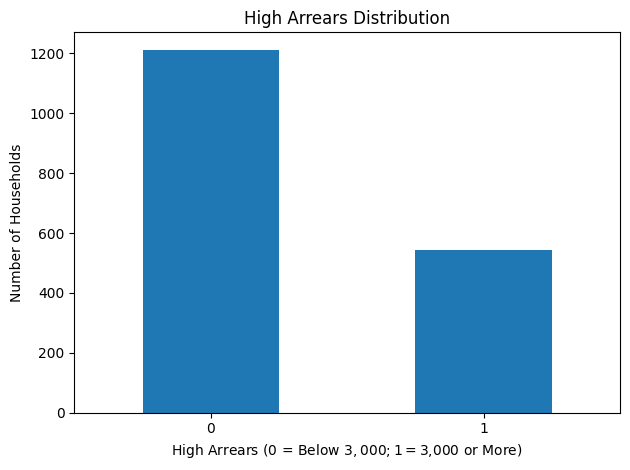

In [7]:
arrears_counts = df['high_arrears'].value_counts().sort_index()

arrears_counts.plot(kind='bar')
plt.title('High Arrears Distribution')
plt.xlabel('High Arrears (0 = Below $3,000; 1 = $3,000 or More)')
plt.ylabel('Number of Households')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

The larger class is 0 with 1,210 household owing less than $3,000. A model could reach a very high accuracy (69%) but it would not be representative of the entire dataset and would miss every high-arrear houehold.

## Part 2 - Prepare the Data
### 3. Select features and split (10 points)
- Create X by dropping record_id, past_due_rent, and high_arrears. Set y = high_arrears.
- Split the data once into training and testing sets.
- Answer: Why do we keep a separate test set?

In [8]:
X = df.drop(columns=['record_id', 'past_due_rent', 'high_arrears'])
y = df['high_arrears']

In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [10]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1403, 12)
X_test: (351, 12)
y_train: (1403,)
y_test: (351,)


We keep a test set separate to see how good the model is at predicting households it did not train itself on.If we just used the entire dataset to train the model we would have no idea how good the model would be at predicting data from the entire population. Stratificiation can keep the proportions of high past rent due household similar in both the train and test sets.


### 4. Build one reusable preprocessor (15 points)
- Identify numerical and categorical columns with select_dtypes.
- Numerical: fill missing values using median and apply StandardScaler.
- Categorical: fill missing values using most_frequent and apply OneHotEncoder(handle_unknown="ignore").
- Combine with ColumnTransformer. You may reuse the class example.
- Answer: Why is scaling helpful for KNN and SVC?

In [11]:
num = X.select_dtypes(include="number").columns.tolist()
cat = X.select_dtypes(exclude="number").columns.tolist()

print("Numerical Variables/Features:", num)
print("Categorical Variables/Features:", cat)

Numerical Variables/Features: ['adults_in_household', 'children_in_household', 'monthly_household_income', 'monthly_rent']
Categorical Variables/Features: ['household_has_65plus', 'income_sources', 'employment_status', 'has_housing_voucher', 'eviction_in_progress', 'behind_on_utilities', 'main_reason_behind_on_rent', 'intake_quarter']


#### Prepare the numerical variables

In [12]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

#### Prepare the categorical variables

In [13]:
from sklearn.preprocessing import OneHotEncoder

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

#### Combine the preprocessing steps

In [14]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer([
    ('numerical', numerical_pipeline, num),
    ('categorical', categorical_pipeline, cat)
])

Scaling helps KNN and SVC because Income an drent could have too much influence on them with their larger numerical values comparatively. Keeping preprocessing inside the pipeline can ensure their is no mixing and the scaling is learned from only training not test.

## Part 3 - Train and Compare Five Models
### 5. Train the five classifiers (20 points)
- Build five pipelines with the same preprocessor and training set: LogisticRegression(max_iter=1000), KNeighborsClassifier(n_neighbors=5), DecisionTreeClassifier(max_depth=5, random_state=42), RandomForestClassifier(n_estimators=100, random_state=42), and SVC().
- Fit each pipeline and report test accuracy, recall, and F1 for class 1. Use a short, repeated code pattern; you do not need a loop or custom functions.

#### Build the Logistic Regression model

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score, f1_score

logistic_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('logistic_model', LogisticRegression(max_iter=1000))
])

logistic_pipeline.fit(X_train, y_train)

logistic_pred = logistic_pipeline.predict(X_test)

In [16]:
logistic_accuracy = accuracy_score(y_test, logistic_pred)
logistic_recall = recall_score(y_test, logistic_pred)
logistic_f1 = f1_score(y_test, logistic_pred)

print("Logistic Regression Accuracy:", logistic_accuracy)
print("Logistic Regression Recall:", logistic_recall)
print("Logistic Regression F1:", logistic_f1)

Logistic Regression Accuracy: 0.6951566951566952
Logistic Regression Recall: 0.30275229357798167
Logistic Regression F1: 0.3815028901734104


The *logistic regression model* had an accuracy of about 69.5%, recall of 30.3%, and F1 of 0.382. Although it had a accuracy of 69.5%, the model did not do a good job of finding high-arrear households.

#### Build the KNN model

In [17]:
from sklearn.neighbors import KNeighborsClassifier

knn_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('knn_model', KNeighborsClassifier(n_neighbors=5))
])

knn_pipeline.fit(X_train, y_train)

knn_pred = knn_pipeline.predict(X_test)

In [18]:
knn_accuracy = accuracy_score(y_test, knn_pred)
knn_recall = recall_score(y_test, knn_pred)
knn_f1 = f1_score(y_test, knn_pred)

print("KNN Accuracy:", knn_accuracy)
print("KNN Recall:", knn_recall)
print("KNN F1:", knn_f1)

KNN Accuracy: 0.6809116809116809
KNN Recall: 0.3761467889908257
KNN F1: 0.422680412371134


The *KNN* had an accuracy of 68.1%, recall of 37.6%, and F1 of 0.423. With a higher F1 and catching a much larger share of high-arrear cases, it still missed most of them.

#### Build the Decision Tree model

In [19]:
from sklearn.tree import DecisionTreeClassifier

tree_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('tree_model', DecisionTreeClassifier(max_depth=5, random_state=42))
])

tree_pipeline.fit(X_train, y_train)

tree_pred = tree_pipeline.predict(X_test)

In [20]:
tree_accuracy = accuracy_score(y_test, tree_pred)
tree_recall = recall_score(y_test, tree_pred)
tree_f1 = f1_score(y_test, tree_pred)

print("Decision Tree Accuracy:", tree_accuracy)
print("Decision Tree Recall:", tree_recall)
print("Decision Tree F1:", tree_f1)

Decision Tree Accuracy: 0.6951566951566952
Decision Tree Recall: 0.3302752293577982
Decision Tree F1: 0.4022346368715084


The Decision Tree model had an accuracy of 69.5%, recall of 33.0%, and F1 at 0.402. Again, catching about one third of the hihg-arrear houses and preformignn slighly better than the logistical regression model on recall and F1.

#### Build the Random Forest model

In [21]:
from sklearn.ensemble import RandomForestClassifier

forest_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('forest_model', RandomForestClassifier(n_estimators=100, random_state=42))
])

forest_pipeline.fit(X_train, y_train)

forest_pred = forest_pipeline.predict(X_test)

In [22]:
forest_accuracy = accuracy_score(y_test, forest_pred)
forest_recall = recall_score(y_test, forest_pred)
forest_f1 = f1_score(y_test, forest_pred)

print("Random Forest Accuracy:", forest_accuracy)
print("Random Forest Recall:", forest_recall)
print("Random Forest F1:", forest_f1)

Random Forest Accuracy: 0.7037037037037037
Random Forest Recall: 0.3211009174311927
Random Forest F1: 0.40229885057471265


Accuracy at about 70.4%, recall at 32.1% and F1 at 0.402. The overall accuracy of this model was higher than KNN, but the recall and F1 are lower, and it identified a smaller share of high-arrear households.

#### Build the SVC model

In [23]:
from sklearn.svm import SVC

svc_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('svc_model', SVC())
])

svc_pipeline.fit(X_train, y_train)

svc_pred = svc_pipeline.predict(X_test)

In [24]:
svc_accuracy = accuracy_score(y_test, svc_pred)
svc_recall = recall_score(y_test, svc_pred)
svc_f1 = f1_score(y_test, svc_pred)

print("SVC Accuracy:", svc_accuracy)
print("SVC Recall:", svc_recall)
print("SVC F1:", svc_f1)

SVC Accuracy: 0.7065527065527065
SVC Recall: 0.22935779816513763
SVC F1: 0.32679738562091504


The *SVC* model has an accuracy of about 71%, recall of 23%, and F1 of 0.327. Its accuracy was higher than any other model but did not identify as many high-arrear household with the lowest recall and F1. This is a good example as to how accuracy can be a misleading representation of a model.


### 6. Compare the models (10 points)
- Put the test results in one table with columns: Model, Accuracy, Recall, F1.
- Create one confusion matrix for the model with the highest test F1.
- Answer: Which model catches the highest proportion of high-arrears households? What does a missed case mean for SLCM?

In [25]:
comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'KNN',
        'Decision Tree',
        'Random Forest',
        'SVC'
    ],
    'Accuracy': [logistic_accuracy, knn_accuracy, tree_accuracy, forest_accuracy, svc_accuracy],
    'Recall': [logistic_recall, knn_recall, tree_recall, forest_recall, svc_recall],
    'F1': [logistic_f1, knn_f1, tree_f1, forest_f1, svc_f1]
})

comparison

,Model,Accuracy,Recall,F1
0,Logistic Regression,0.695157,0.302752,0.381503
1,KNN,0.680912,0.376147,0.422680
2,Decision Tree,0.695157,0.330275,0.402235
3,Random Forest,0.703704,0.321101,0.402299
4,SVC,0.706553,0.229358,0.326797


In [26]:
comparison.sort_values(by='F1', ascending=False)

,Model,Accuracy,Recall,F1
1,KNN,0.680912,0.376147,0.422680
3,Random Forest,0.703704,0.321101,0.402299
2,Decision Tree,0.695157,0.330275,0.402235
0,Logistic Regression,0.695157,0.302752,0.381503
4,SVC,0.706553,0.229358,0.326797


#### Confusion matrix


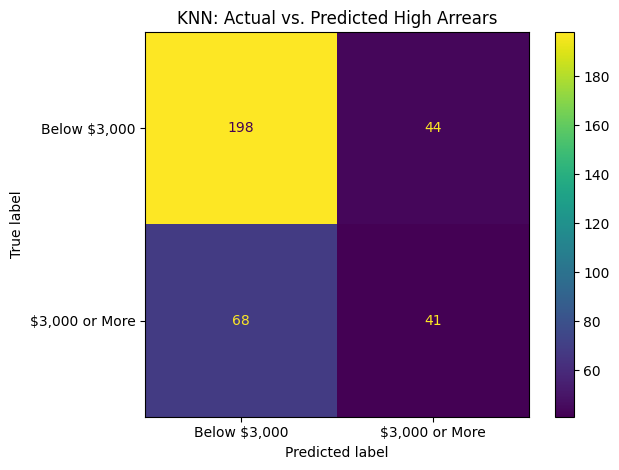

In [27]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test, knn_pred,
    display_labels=['Below $3,000', '$3,000 or More']
)
plt.title('KNN: Actual vs. Predicted High Arrears')
plt.tight_layout()
plt.show()

KNN has the highest recall and F1. It identified 41 high-arrear households but missed 68, and it flagged 44 households below the threshold. This could mena that a household with overdue rent could get overlooked by the model, whihc is problematic and means an unreliable model.

### 7. Try a small GridSearchCV (15 points)
- Tune only two models on the training set with cv=3 and scoring="f1".
- For KNN, try n_neighbors = [3, 5, 7].
- For Random Forest, try max_depth = [3, 5, None] (keep n_estimators=100).
- Print best_params_ and best_score_ for each search. No extra charts or second search are needed.
- Answer: Which has the higher best cross-validation F1? Why is GridSearchCV fitted on training data only?

#### Tune KNN

In [28]:
from sklearn.model_selection import GridSearchCV

knn_grid = {'knn_model__n_neighbors': [3, 5, 7]}

knn_search = GridSearchCV(
    knn_pipeline,
    knn_grid,
    cv=3,
    scoring='f1'
)

knn_search.fit(X_train, y_train)

print('Best KNN parameters:', knn_search.best_params_)
print('KNN CV F1:', knn_search.best_score_)

Best KNN parameters: {'knn_model__n_neighbors': 7}
KNN CV F1: 0.4854649923374277


#### Tune Random Forest

In [29]:
forest_grid = {'forest_model__max_depth': [3, 5, None]}

forest_search = GridSearchCV(
    forest_pipeline,
    forest_grid,
    cv=3,
    scoring='f1'
)

forest_search.fit(X_train, y_train)

print('Best Random Forest parameters:', forest_search.best_params_)
print('Random Forest CV F1:', forest_search.best_score_)

Best Random Forest parameters: {'forest_model__max_depth': None}
Random Forest CV F1: 0.4574743145651916


KNN had the better cross-validation F! at about 0.485 with 7 neighbors compared with random forest at 0.457 and no maximum depth. GridsearchCV compares settings using folds within the training data where the test data remains separate to check performance.

## Part 4 - Explain the Results
### 8. Interpret your comparison (8 points)

KNN looks to be the most promising model because it had the highest F! and recall. But, the recall of 37.6% means it still missed a massive amount (over half) of the hihg-arrear households. The more complex models did not perform better than the KNN on those fields of measurement, and the SLCM should pay attention to errors in both missed households and false alarms. They have a large affect on the well-being of the people that are affected, and are not accurately represented in the model.


### 9. Recommendation to SLCM (7 points)

I tested whether household and housing information could help identify households owing at least $3,000 in rent. The KNN model performed the best, but only managed to catch about 38% of the high-arrear households in our test data. These results suggest that there there is some help with the model at idetnifying these high-arrear households, but it is not to be relied on by any means. Also, correlation is not causation, and the predictions must not be used alone to determine elibility for assistance.


